# 2. Chunking, embeddings and vector search

The *indexing* half of RAG: split documents into chunks, turn each chunk into a vector, store the vectors so we
can find the chunks closest to a question.

> **Course concepts used here**
>
| Course notebook | What we use it for |
|---|---|
| `I_Embeddings/1-2` | what an embedding is, cosine similarity |
| `N_LangChain/03_langchain-RAG` | text splitters, embeddings, vector store, similarity search |
| `N_LangChain/08` (FAISS) | local FAISS vector store instead of Pinecone |
| `F_Machine_Learning_Unsupervised` | PCA to look at the embedding space in 2D |

In [1]:
import os, sys, warnings
from pathlib import Path

# Run from the repo root so `ironstore_assistant` can be imported
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
pd.set_option("display.max_colwidth", 120)

## 2.1 Embeddings in one picture

An embedding maps text to a vector so that texts with similar meaning are close. We compare one question with four
sentences using the embeddings of the project's index (`ensure_index()` builds it the first time; embedding ~3,800
chunks costs a few cents with OpenAI).

In [2]:
import json
import numpy as np
from ironstore_assistant import config
from ironstore_assistant.build_index import ensure_index
from ironstore_assistant.index import load_index

ensure_index()
store = load_index()
print("embeddings:", json.loads((config.INDEX_DIR / "manifest.json").read_text())["model"])

emb = store.embeddings
question = "How many days per week can I work remotely?"
sentences = [
    "Hybrid employees may work remotely up to three days per week.",   # same words
    "Staff are allowed to do their job from home on some days.",       # same meaning, different words
    "Passwords must be at least 14 characters long.",
    "The sofa costs 899 euros and is in stock.",
]
q = np.array(emb.embed_query(question))
scores = np.array(emb.embed_documents(sentences)) @ q   # normalised vectors: dot product = cosine similarity
pd.DataFrame({"sentence": sentences, "cosine similarity": scores.round(2)})

embeddings: tfidf


,sentence,cosine similarity
0,Hybrid employees may work remotely up to three days per week.,0.55
1,Staff are allowed to do their job from home on some days.,0.23
2,Passwords must be at least 14 characters long.,0.17
3,The sofa costs 899 euros and is in stock.,0.05


With the offline **TF-IDF** embeddings, the second sentence scores low: TF-IDF only matches shared *words*,
and "from home" shares none with "remotely". Neural embeddings such as OpenAI's (or the sentence-transformers model
from `I_Embeddings/2`) place it close to the question, because they encode *meaning*. That is why OpenAI embeddings
are the default, and why multi-query retrieval (notebook 4) helps when embeddings are weak.

## 2.2 Chunking

A whole policy (6-7 pages) is too big to send for every question, and one vector for the whole document would blur
all its topics together. We split it into ~1,000-character chunks with 150 characters of overlap, **page by page**
so every chunk knows its page number (needed for citations).

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from ironstore_assistant.ingest import extract_zip, load_pdf

pdfs = extract_zip()
remote = load_pdf(next(p for p in pdfs if "Remote_Work" in p.name))
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
chunks = splitter.split_text(remote.pages[1])
print(f"page 2 has {len(remote.pages[1])} characters -> {len(chunks)} chunks of {[len(c) for c in chunks]} chars")
print(chunks[0][:400])

page 2 has 2359 characters -> 3 chunks of [918, 919, 805] chars
IronStore uses the following working models:
Office-based: Work is primarily performed at an assigned IronStore location.
Hybrid: Work is performed at an IronStore location on designated days and remotely on other working days.
Remote-first: Work is normally performed remotely, with attendance required for team events, planning
sessions, training, or other business needs.
The hiring manager and Pe


### Don't cut sentences at page breaks

Our first version chunked **page by page**. Look at the end of page 2 of the Refund policy:

In [4]:
refund = load_pdf(next(p for p in pdfs if "Refund_and_Complaint" in p.name))
print("...end of page 2:  ", repr(refund.pages[1][-120:]))
print("start of page 3:   ", repr(refund.pages[2][:60]))

...end of page 2:   'Unless a\nlonger legal or commercial period applies, unopened and resalable goods are accepted within 30 calendar days of'
start of page 3:    'delivery. Product-specific exceptions include:\nPersonalised '


The answer to *"what is the return window?"* (30 calendar days of delivery) is cut in half by the page break,
so no page-level chunk contains the full sentence. That's exactly the question that came back with **low
confidence** in the first deployment. Now `split_across_pages` chunks the whole document and records which pages
each chunk spans, so citations become *p. 2–3*:

In [5]:
from ironstore_assistant.ingest import split_across_pages

splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150, add_start_index=True)
for text, first, last in split_across_pages(refund.pages, splitter):
    if "30 calendar days" in text:
        print(f"pages {first}-{last}:")
        print(text[text.find("For standard"):][:330])

pages 2-3:
For standard consumer returns, the applicable country return period is shown in the customer’s order terms. Unless a
longer legal or commercial period applies, unopened and resalable goods are accepted within 30 calendar days of
delivery. Product-specific exceptions include:
Personalised goods: normally non-returnable unless fau


**Catalogs are chunked differently: one chunk per product.** A fixed-size splitter would cut a product in half
(price in one chunk, availability in the next) or glue two products together, and the model could then mix up
their prices.

In [6]:
from ironstore_assistant.ingest import ingest

result = ingest(pdfs)
docs = result.documents
pd.Series([d.metadata["kind"] for d in docs]).value_counts()

product          3252
policy            296
catalog_notes     183
Name: count, dtype: int64

In [7]:
product_chunk = next(d for d in docs if d.metadata.get("sku") == "FUR-SOF-NOR-LYSA-GRY")
print(product_chunk.page_content[:500])
product_chunk.metadata

[IronStore Product Catalog — Furniture | Product catalog | last reviewed August 2026] | section: Living Room Seating | page 1
1. Nordholm Lysa 3-Seater Sofa
SKU: FUR-SOF-NOR-LYSA-GRY
Category: Furniture > Living Room > Sofas
Short description: Three-seat fabric sofa with removable seat cushions and a solid timber frame.
Price: €899.00
Key specifications:
Brand: Nordholm
Upholstery: Polyester-linen blend, charcoal grey
Dimensions: 218 × 92 × 84 cm
Seat height: 46 cm
Seat depth: 58 cm
Frame: Kiln-


{'source': 'IronStore_Product_Catalog_Furniture.pdf',
 'title': 'IronStore Product Catalog — Furniture',
 'doc_type': 'catalog',
 'area': 'Product catalog',
 'doc_id': '',
 'version': '',
 'last_reviewed': 'August 2026',
 'effective_date': '',
 'status': 'current',
 'id_conflict': False,
 'page': 1,
 'kind': 'product',
 'sku': 'FUR-SOF-NOR-LYSA-GRY',
 'product_name': 'Nordholm Lysa 3-Seater Sofa',
 'chunk_id': 1639}

Notice the first line of every chunk, e.g. `[IronStore Product Catalog — Furniture | Product catalog | last
reviewed August 2026] | section: … | page 1`. Prepending the title and status helps both the retriever (the
words are now in the vector) and the LLM (it sees where the text comes from).

## 2.3 The FAISS index

The index loaded above holds one vector per chunk, plus each chunk's text and metadata.

In [8]:
print(json.loads((config.INDEX_DIR / "manifest.json").read_text()))
print("vectors in FAISS:", store.index.ntotal)

{'provider': 'tfidf', 'model': 'tfidf', 'chunks': 3731, 'built_at': '2026-10-30 13:19:00', 'index_version': 2}
vectors in FAISS: 3731


In [9]:
def search(query, k=4, **filter_kwargs):
    rows = []
    for d, score in store.similarity_search_with_score(query, k=k, **filter_kwargs):
        rows.append({"score": round(float(score), 3), "document": d.metadata["title"], "page": d.metadata["page"],
                     "status": d.metadata["status"]})
    return pd.DataFrame(rows)

search("How many days per week can hybrid employees work from home?")

,score,document,page,status
0,0.696,Remote Work Policy,1,current
1,0.671,Remote Work Policy,1,current
2,0.668,Remote Work Policy,3,current
3,0.668,Remote Work Policy,2,current


In [10]:
search("Who must approve a contract above 100,000 euros?")

,score,document,page,status
0,0.760,Budget Approval Workflow,3,current
1,0.758,Budget Approval Workflow,3,current
2,0.738,Contract Approval Workflow,4,current
3,0.652,Budget Approval Workflow,3,current


## 2.4 Metadata filters: keeping the outdated catalog out

The 2021 catalog contains a *"24\" Full HD Office Monitor"*. Without a filter it shows up in the results:

In [11]:
search("IronStore 24 inch Full HD office monitor price")

,score,document,page,status
0,0.471,IronStore Product Catalog — Electronics,7,current
1,0.470,IronStore Product Catalog — All categories (2021 edition),1,outdated
2,0.454,IronStore Product Catalog — Computer Accessories,11,current
3,0.448,IronStore Product Catalog — Gaming Accessories,16,current


In [12]:
search("IronStore 24 inch Full HD office monitor price", fetch_k=100,
       filter=lambda md: md["status"] != "outdated")

,score,document,page,status
0,0.471,IronStore Product Catalog — Electronics,7,current
1,0.454,IronStore Product Catalog — Computer Accessories,11,current
2,0.448,IronStore Product Catalog — Gaming Accessories,16,current
3,0.429,IronStore Product Catalog — Electronics,1,current


With the filter (what `Retriever.search` does by default), the assistant only sees current catalogs and will
say the product isn't in them, instead of quoting a 2021 price as if it were valid today.

## 2.5 Hybrid search: meaning + keywords

Embeddings capture meaning, but they can rank a passage low when it uses specific words (*"30 calendar days"*,
a SKU, a product name). Classic **TF-IDF keyword search** (from the NLP module) is the opposite. The `Retriever`
runs both for every query and merges the rankings with reciprocal-rank fusion (more on fusion in notebook 4).

In [13]:
from ironstore_assistant.rag import RetrievalTrace, Retriever

retriever = Retriever(store)
question = "What is the return window for customers?"
trace = RetrievalTrace()
final = retriever.search([question], trace=trace)

def show(method):
    return [f'{retriever.docs[h.chunk_id].metadata["title"]} p.{retriever.docs[h.chunk_id].metadata["page"]}'
            for h in trace.hits if h.method == method][:5]

pd.DataFrame({"🧭 semantic (FAISS)": show("semantic"), "🔤 keywords (TF-IDF)": show("keyword")})

,🧭 semantic (FAISS),🔤 keywords (TF-IDF)
0,Returns & Reverse Logistics Procedure p.1,Refund & Complaint Handling Policy p.7
1,Returns & Reverse Logistics Procedure p.2,Refund & Complaint Handling Policy p.2
2,Returns & Reverse Logistics Procedure p.4,Refund & Complaint Handling Policy p.2
3,Refund & Complaint Handling Policy p.2,Sales Commission Plan p.4
4,Returns & Reverse Logistics Procedure p.4,Returns & Reverse Logistics Procedure p.1


In [14]:
pd.DataFrame([{"rank": i, "document": d.metadata["title"],
               "pages": f'{d.metadata["page"]}-{d.metadata.get("page_end", d.metadata["page"])}',
               "has the 30-day rule": "30 calendar days" in d.page_content}
              for i, d in enumerate(final, 1)])

,rank,document,pages,has the 30-day rule
0,1,Returns & Reverse Logistics Procedure,1-2,False
1,2,Refund & Complaint Handling Policy,2-3,True
2,3,Refund & Complaint Handling Policy,2-2,False
3,4,Terms of Service Overview,3-4,False
4,5,Customer Support Knowledge Base Style Guide,4-4,False
5,6,Returns & Reverse Logistics Procedure,2-3,False
6,7,Refund & Complaint Handling Policy,7-7,False
7,8,Returns & Reverse Logistics Procedure,2-2,False


At most 3 chunks per document are kept, so a long document can't crowd out the one that holds the answer
(here the Returns procedure, which only says *"see the applicable return period"*).

## 2.6 Looking at the embedding space (PCA)

FAISS stores the vectors, so we can pull them out and project them to 2D, like in the unsupervised-learning
module. Policy chunks from the same department should cluster together.

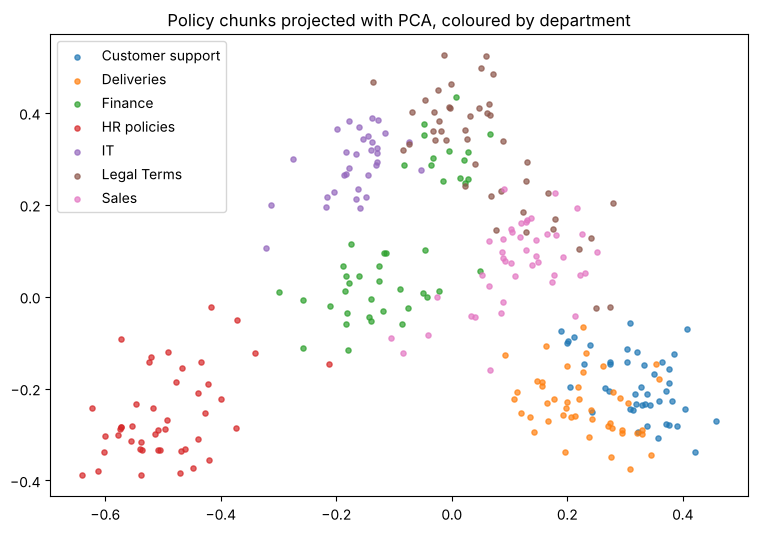

In [15]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

ids = list(store.index_to_docstore_id.items())
pol = [(i, store.docstore.search(doc_id)) for i, doc_id in ids]
pol = [(i, d) for i, d in pol if d.metadata["doc_type"] == "policy"]
X = np.vstack([store.index.reconstruct(int(i)) for i, _ in pol])
areas = [d.metadata["area"] for _, d in pol]

xy = PCA(n_components=2, random_state=0).fit_transform(X)
plt.figure(figsize=(9, 6))
for area in sorted(set(areas)):
    m = np.array(areas) == area
    plt.scatter(xy[m, 0], xy[m, 1], s=14, label=area, alpha=0.7)
plt.legend(); plt.title("Policy chunks projected with PCA, coloured by department"); plt.show()

Next: using these chunks to answer questions with citations → **notebook 3**.